In [1]:
%pip install pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 4.1 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 8.0 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.3 MB 10.1 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 11.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 15.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ----------------------- ---------------- 4.2/7.3 MB 19.5 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 18.3 MB/s eta 0:00:00

   ---------------------------------------- 0/8 [pyparsing]
   ---------------------------------------- 0/8 [pyparsing]
   ---------------------------------------- 0/8 [pyparsing

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

matches = pd.read_csv("epl_matches_clean.csv", parse_dates=["date"])
team_stats = pd.read_csv("epl_team_stats_clean.csv")

print("matches:", matches.shape)
print("team_stats:", team_stats.shape)
matches.head()

matches: (2970, 10)
team_stats: (5940, 96)


,game_id,season,match_week,date,home_team_id,away_team_id,home_team,away_team,home_goals,away_goals
0,e3c3ddf0,2017-2018,1,2017-08-11 19:45:00,18bb7c10,a2d435b3,Arsenal,Leicester City,4,3
1,60f6cc1d,2017-2018,1,2017-08-12 12:30:00,2abfe087,822bd0ba,Watford,Liverpool,3,3
2,2d369d17,2017-2018,1,2017-08-12 15:00:00,47c64c55,f5922ca5,Crystal Palace,Huddersfield Town,0,3
3,684f704a,2017-2018,1,2017-08-12 15:00:00,60c6b05f,4ba7cbea,West Bromwich Albion,Bournemouth,1,0
4,71b00bca,2017-2018,1,2017-08-12 15:00:00,cff3d9bb,943e8050,Chelsea,Burnley,2,3


Bảng matches có 2970 dòng × 10 cột, bảng team_stats có 5940 dòng × 96 cột (đúng bằng 2 × 2970, tức mỗi trận có đủ thống kê của 2 đội). Cả 10 cột của matches đều đủ 2970 giá trị, không có ô thiếu. Cột date đã đúng kiểu datetime64. Các cột mã (game_id, home_team_id, away_team_id) và tên mùa/đội là kiểu chữ (object); số bàn thắng và vòng đấu là kiểu số nguyên.

# CÁC LỆNH NHÌN DỮ LIỆU

In [3]:
matches.shape
matches.head(10)
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2970 entries, 0 to 2969
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   game_id       2970 non-null   object        
 1   season        2970 non-null   object        
 2   match_week    2970 non-null   int64         
 3   date          2970 non-null   datetime64[ns]
 4   home_team_id  2970 non-null   object        
 5   away_team_id  2970 non-null   object        
 6   home_team     2970 non-null   object        
 7   away_team     2970 non-null   object        
 8   home_goals    2970 non-null   int64         
 9   away_goals    2970 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 232.2+ KB


# CHỌN CỘT VÀ LỌC DÒNG

In [4]:
matches["home_goals"]
matches[["home_goals", "home_team"]]
matches[matches["home_goals"] > 3]

,game_id,season,match_week,date,home_team_id,away_team_id,home_team,away_team,home_goals,away_goals
0,e3c3ddf0,2017-2018,1,2017-08-11 19:45:00,18bb7c10,a2d435b3,Arsenal,Leicester City,4,3
9,f5d1f6f4,2017-2018,1,2017-08-13 16:00:00,19538871,7c21e445,Manchester United,West Ham United,4,0
29,e4374144,2017-2018,3,2017-08-27 16:00:00,822bd0ba,18bb7c10,Liverpool,Arsenal,4,0
30,39dcce19,2017-2018,4,2017-09-09 12:30:00,b8fd03ef,822bd0ba,Manchester City,Liverpool,5,0
49,94bab527,2017-2018,5,2017-09-17 16:00:00,19538871,d3fd31cc,Manchester United,Everton,4,0
...,...,...,...,...,...,...,...,...,...,...
2946,4254acea,2024-2025,32,2025-04-13 16:30:00,b2b47a98,19538871,Newcastle United,Manchester United,4,1
2948,6e87f6cf,2024-2025,29,2025-04-16 19:30:00,b2b47a98,47c64c55,Newcastle United,Crystal Palace,5,0
2949,36afccb6,2024-2025,33,2025-04-19 15:00:00,cd051869,d07537b9,Brentford,Brighton & Hove Albion,4,2
2953,45a3960e,2024-2025,33,2025-04-19 17:30:00,8602292d,b2b47a98,Aston Villa,Newcastle United,4,1


Có 259 trận đội nhà ghi từ 4 bàn trở lên, chiếm khoảng 8,7% tổng số trận (259/2970). Đây là các trận thắng đậm, rất ít so với toàn bộ dữ liệu. Điều này cho thấy phân bố số bàn thắng lệch phải (nhiều trận ít bàn, ít trận nhiều bàn).

# TẠO CÁC CỘT PHỤ VÀ KIỂM TRA SỐ TRẬN MỖI MÙA

In [5]:
matches["total_goals"] = matches["home_goals"] + matches["away_goals"]
matches["goal_diff"] = matches["home_goals"] - matches["away_goals"]
matches["result"] = np.select(
    [matches["goal_diff"] > 0, matches["goal_diff"] < 0],
    ["H", "A"],
    default="D"
)

print("Số trận theo mùa (đủ là 380):")
display(matches.groupby("season").size().rename("so_tran"))

Số trận theo mùa (đủ là 380):


season
2017-2018    380
2018-2019    380
2019-2020    380
2020-2021    380
2021-2022    380
2022-2023    380
2023-2024    380
2024-2025    310
Name: so_tran, dtype: int64

Bảng matches có 2970 trận, thấp hơn 70 trận so với lý thuyết (8 mùa × 380 = 3040). Bảy mùa từ 2017-2018 đến 2023-2024 đều đủ 380 trận. Riêng mùa 2024-2025 chỉ có 310 trận (thiếu 70 trận, tương đương khoảng 7 vòng cuối mùa). Nguyên nhân: nguồn dữ liệu của thư viện premier_league chưa cập nhật đến hết mùa này. Khuyến nghị: khi chia tập huấn luyện/kiểm tra theo thời gian, cần nhớ mùa 2024-2025 chưa hoàn chỉnh. Khi tính bảng xếp hạng hoặc thống kê theo mùa, không nên so sánh trực tiếp tổng điểm của mùa này với các mùa khác (dùng trung bình mỗi trận thì công bằng hơn).

# TỈ LỆ THẮNG/HÒA/THUA

result
H    0.444
A    0.327
D    0.229
Name: proportion, dtype: float64


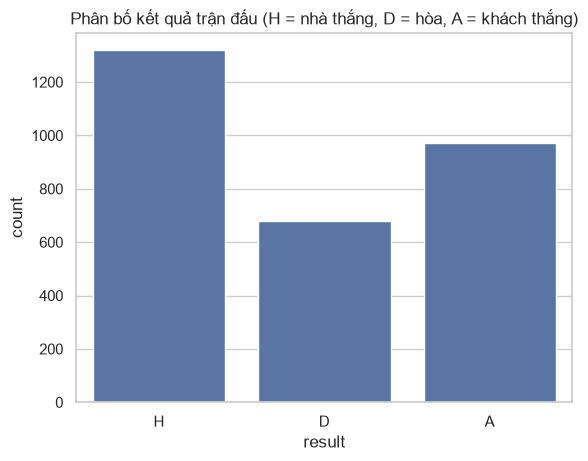

In [6]:
print(matches["result"].value_counts(normalize=True).round(3))

sns.countplot(x="result", data=matches, order=["H", "D", "A"])
plt.title("Phân bố kết quả trận đấu (H = nhà thắng, D = hòa, A = khách thắng)")
plt.savefig("hinh_01_ketqua.png", dpi=150, bbox_inches="tight")
plt.show()

Trên 2970 trận, đội nhà thắng 44,4% (khoảng 1319 trận), đội khách thắng 32,7% (khoảng 971 trận), hòa 22,9% (khoảng 680 trận). Đội nhà thắng nhiều hơn đội khách 11,7 điểm phần trăm, cho thấy sân nhà có lợi thế rõ rệt. Baseline “luôn dự đoán đội nhà thắng” đạt độ chính xác 44,4%, và model phải vượt mức này mới có giá trị (nếu đoán ngẫu nhiên ba kết quả thì chỉ đạt khoảng 33%). Kết quả hòa chiếm tỷ lệ thấp nhất (22,9%) nhưng thường là lớp khó dự đoán nhất, nên cần chú ý khi đánh giá model.

# PHÂN BỐ SỐ BÀN THẮNG

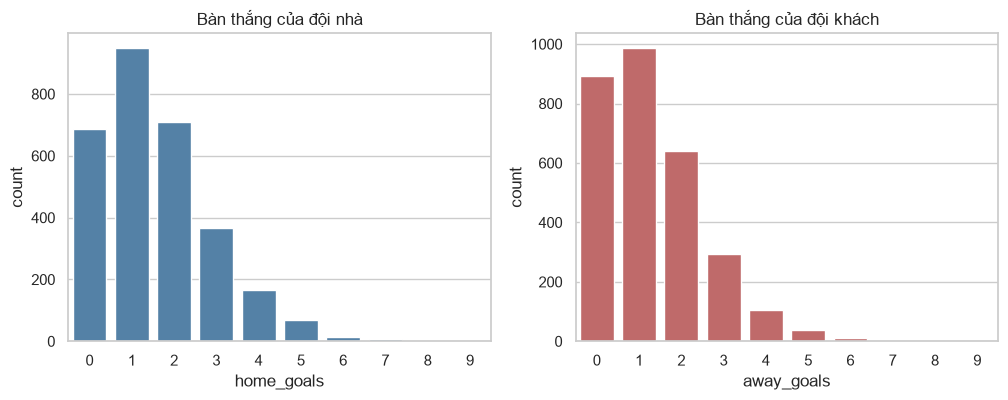

      home_goals  away_goals
mean        1.56        1.30
var         1.78        1.49
Tỷ lệ trận trên 2.5 bàn: 0.546


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="home_goals", data=matches, ax=axes[0], color="steelblue")
axes[0].set_title("Bàn thắng của đội nhà")
sns.countplot(x="away_goals", data=matches, ax=axes[1], color="indianred")
axes[1].set_title("Bàn thắng của đội khách")
plt.savefig("hinh_02_phanbo_bantahng.png", dpi=150, bbox_inches="tight")
plt.show()

print(matches[["home_goals", "away_goals"]].agg(["mean", "var"]).round(2))
print("Tỷ lệ trận trên 2.5 bàn:", round((matches["total_goals"] > 2.5).mean(), 3))

Đội nhà ghi trung bình 1,56 bàn/trận, đội khách 1,30 bàn/trận (chênh 0,26 bàn), thể hiện lợi thế sân nhà. Phân bố của cả hai đội đều lệch phải: phần lớn trận có từ 0 đến 2 bàn, giá trị phổ biến nhất là 1 bàn (đội nhà khoảng 950 trận, đội khách khoảng 985 trận), số trận giảm nhanh từ 3 bàn trở lên và gần như không còn ở mức 6 bàn trở lên. Đội khách bị “tịt” bàn (0 bàn) nhiều hơn rõ rệt (khoảng 890 trận, so với khoảng 685 trận của đội nhà). Phương sai (1,78 và 1,49) chỉ cao hơn trung bình khoảng 14%, tức gần bằng nhau, nên số bàn thắng xấp xỉ phân phối Poisson (có thể phân tán nhẹ hơn lý thuyết). Đề xuất cho nhóm model: Poisson Regression là lựa chọn phù hợp, nên dự đoán riêng số bàn của đội nhà và đội khách. Có 54,6% trận có từ 3 bàn trở lên (trên 2,5 bàn).

# XU HƯỚNG THEO MÙA

,so_tran,home_goals,away_goals,total_goals
season,,,,
2017-2018,380,1.53,1.15,2.68
2018-2019,380,1.57,1.25,2.82
2019-2020,380,1.52,1.21,2.72
2020-2021,380,1.35,1.34,2.69
2021-2022,380,1.51,1.31,2.82
2022-2023,380,1.63,1.22,2.85
2023-2024,380,1.80,1.48,3.28
2024-2025,310,1.55,1.44,2.99


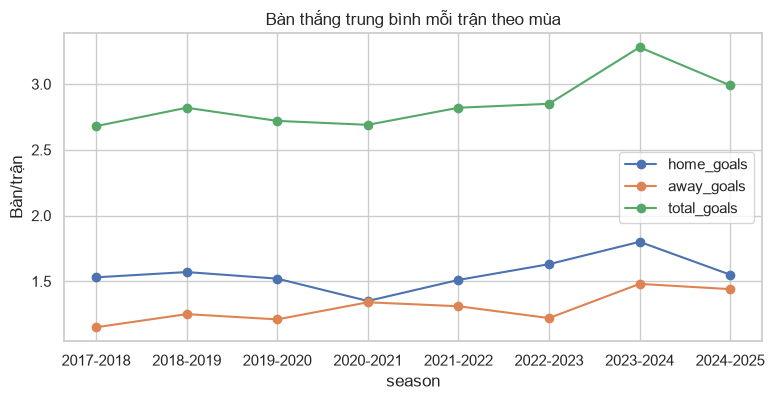

result,A,D,H
season,,,
2017-2018,0.284,0.261,0.455
2018-2019,0.337,0.187,0.476
2019-2020,0.305,0.242,0.453
2020-2021,0.403,0.218,0.379
2021-2022,0.339,0.232,0.429
2022-2023,0.287,0.229,0.484
2023-2024,0.324,0.216,0.461
2024-2025,0.342,0.248,0.410


In [9]:
season_summary = matches.groupby("season").agg(
    so_tran=("game_id", "count"),
    home_goals=("home_goals", "mean"),
    away_goals=("away_goals", "mean"),
    total_goals=("total_goals", "mean"),
).round(2)
display(season_summary)

season_summary[["home_goals", "away_goals", "total_goals"]].plot(marker="o", figsize=(9, 4))
plt.title("Bàn thắng trung bình mỗi trận theo mùa")
plt.ylabel("Bàn/trận")
plt.savefig("hinh_03_theo_mua.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.crosstab(matches["season"], matches["result"], normalize="index").round(3))

Số bàn thắng trung bình mỗi trận dao động từ 2,68 (mùa 2017-2018) đến 3,28 (mùa 2023-2024, cao nhất). Từ mùa 2020-2021 trở đi, xu hướng chung là tăng, đặc biệt mùa 2023-2024 tăng vọt (đội nhà 1,80, đội khách 1,48). Mùa 2024-2025 đạt 2,99 bàn/trận nhưng mới có 310/380 trận nên chưa đầy đủ.

Mùa 2020-2021 (không khán giả do COVID-19) là mùa bất thường nhất về lợi thế sân nhà: số bàn đội nhà ghi thấp nhất (1,35) và gần bằng đội khách (1,34), trong khi các mùa khác đội nhà hơn đội khách khoảng 0,3 đến 0,4 bàn. Tỷ lệ đội nhà thắng chỉ 37,9% (thấp nhất), tỷ lệ đội khách thắng 40,3% (cao nhất), đây là mùa duy nhất đội khách thắng nhiều hơn đội nhà. Các mùa còn lại, tỷ lệ đội nhà thắng dao động 41% đến 48,4%. Tỷ lệ hòa dao động 18,7% (mùa 2018-2019) đến 26,1% (mùa 2017-2018).

Kết luận: lợi thế sân nhà không cố định mà thay đổi theo bối cảnh. Đề xuất cho nhóm model: cân nhắc thêm biến đánh dấu “mùa không khán giả” (2020-2021), hoặc thử huấn luyện có/không có mùa này để so sánh kết quả.

# SỨC MẠNH CÁC ĐỘI

,so_tran,gf,ga,ppg
team,,,,
Manchester City,298,2.49,0.84,2.35
Liverpool,296,2.20,0.94,2.21
Arsenal,297,1.89,1.13,1.88
Manchester United,297,1.61,1.22,1.73
Chelsea,297,1.67,1.17,1.72
Tottenham Hotspur,297,1.81,1.29,1.68
Aston Villa,221,1.47,1.44,1.43
Newcastle United,297,1.42,1.38,1.39
Brentford,145,1.48,1.48,1.30


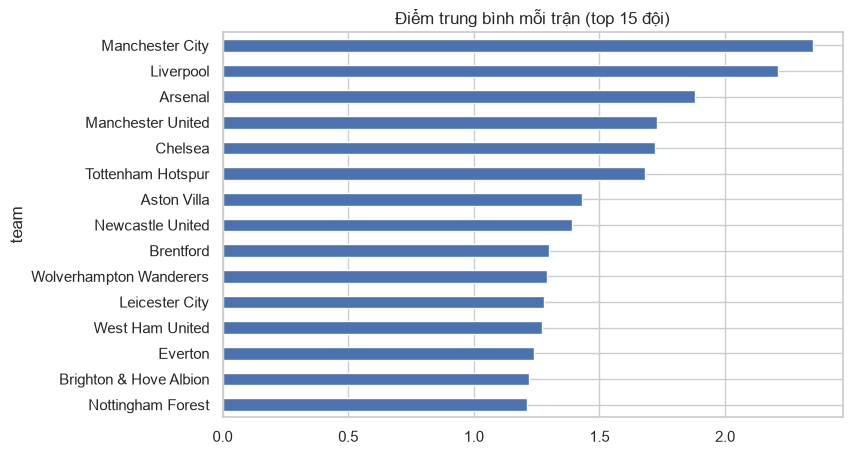

In [10]:
home = matches[["season", "date", "home_team", "home_goals", "away_goals"]].copy()
home.columns = ["season", "date", "team", "gf", "ga"]
home["venue"] = "home"

away = matches[["season", "date", "away_team", "away_goals", "home_goals"]].copy()
away.columns = ["season", "date", "team", "gf", "ga"]
away["venue"] = "away"

long = pd.concat([home, away], ignore_index=True)
long["points"] = np.select(
    [long["gf"] > long["ga"], long["gf"] == long["ga"]], [3, 1], default=0
)

team_table = long.groupby("team").agg(
    so_tran=("gf", "count"),
    gf=("gf", "mean"),
    ga=("ga", "mean"),
    ppg=("points", "mean"),
).sort_values("ppg", ascending=False).round(2)
display(team_table)

team_table["ppg"].head(15).plot.barh(figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title("Điểm trung bình mỗi trận (top 15 đội)")
plt.savefig("hinh_04_top_doi.png", dpi=150, bbox_inches="tight")
plt.show()

Dữ liệu gồm 31 đội, tên đội thống nhất, không bị trùng lặp cách viết. Top 6 theo điểm trung bình mỗi trận (ppg): Manchester City (2,35), Liverpool (2,21), Arsenal (1,88), Manchester United (1,73), Chelsea (1,72), Tottenham (1,68). Manchester City mạnh nhất cả công và thủ (ghi 2,49 bàn, thủng lưới 0,84 bàn mỗi trận). Nhóm cuối: Norwich City (0,57), Huddersfield Town (0,70), Luton Town và Ipswich Town (cùng 0,68), West Bromwich Albion (0,75). Khoảng cách giữa đội đầu và đội cuối là 1,78 điểm/trận, cho thấy sức mạnh các đội chênh lệch rất lớn, nên “đội nào đá” là yếu tố có giá trị dự báo cao. Có thể thấy rõ các nhóm: hai đội đầu bảng nổi trội (trên 2,2), nhóm “Big 6” còn lại (khoảng 1,7 đến 1,9), nhóm giữa bảng (khoảng 1,2 đến 1,4) và nhóm cuối bảng (dưới 1,0).

Lưu ý khi đọc kết quả: (1) Số trận mỗi đội rất khác nhau, từ 31 (Ipswich) đến 298 (Manchester City), do các đội lên/xuống hạng chỉ có mặt vài mùa, nên kết quả của họ kém tin cậy hơn. (2) Những đội chỉ có 1 đến 2 mùa thường là đội đã xuống hạng, nên ppg của họ có xu hướng bị kéo thấp (sai lệch do chọn mẫu). (3) Số trận của các đội mạnh nhất (296 đến 298) không đều nhau do các vòng thiếu của mùa 2024-2025 không ảnh hưởng đồng đều lên mọi đội. (4) Nottingham Forest (107 trận) lọt top 15 với 1,21 điểm/trận, ngang Crystal Palace (297 trận), cho thấy xếp hạng của đội ít trận có thể thiếu ổn định.

# MẠNH SÂN NHÀ HAY SÂN KHÁCH

In [11]:
venue_ppg = long.groupby(["team", "venue"])["points"].mean().unstack()
venue_ppg["chenh_lech"] = venue_ppg["home"] - venue_ppg["away"]
display(venue_ppg.sort_values("chenh_lech", ascending=False).round(2))

print("Điểm trung bình toàn giải - sân nhà:", round(long[long["venue"] == "home"]["points"].mean(), 2))
print("Điểm trung bình toàn giải - sân khách:", round(long[long["venue"] == "away"]["points"].mean(), 2))

venue,away,home,chenh_lech
team,,,
Arsenal,1.57,2.18,0.61
Tottenham Hotspur,1.41,1.95,0.54
Liverpool,1.96,2.45,0.49
Newcastle United,1.16,1.63,0.48
Swansea City,0.63,1.11,0.47
Nottingham Forest,0.98,1.45,0.47
Everton,1.02,1.47,0.45
Brentford,1.08,1.53,0.45
Sheffield United,0.60,1.04,0.44


Điểm trung bình toàn giải - sân nhà: 1.56
Điểm trung bình toàn giải - sân khách: 1.21


Toàn giải, điểm trung bình mỗi trận ở sân nhà là 1,56, sân khách là 1,21 (chênh 0,35 điểm). Đội hưởng lợi thế sân nhà lớn nhất: Arsenal (chênh 0,61: 2,18 sân nhà so với 1,57 sân khách), Tottenham (0,54), Liverpool (0,49), Newcastle (0,48). Ngược lại, Burnley (0,05), Southampton (0,12) gần như không khác biệt giữa sân nhà và sân khách. Manchester City chênh 0,34 nhưng điểm sân khách (2,18) đã cao hơn nhiều đội đá sân nhà, cho thấy đây là đội mạnh toàn diện. Ipswich Town có chênh lệch âm (-0,50: sân nhà 0,44, sân khách 0,93) nhưng chỉ có 31 trận (khoảng 15 trận sân nhà), mẫu quá nhỏ nên không nên kết luận. Kết luận: lợi thế sân nhà có ở hầu hết các đội nhưng mức độ khác nhau, nên model cần biến “sân nhà/sân khách” và có thể thêm hiệu ứng riêng cho từng đội.

# TƯƠNG QUAN VỚI BÀN THẮNG

is_home
True     2970
False    2970
Name: count, dtype: int64


goal_creating_actions_FW     0.750
goal_creating_actions_MF     0.606
xG                           0.603
xAG                          0.529
shots_on_target_FW           0.526
goal_creating_actions_DF     0.521
xA                           0.380
shots_total_FW               0.351
shot_creating_chances_FW     0.334
key_passes                   0.333
touches_att_pen_area_FW      0.331
carries_into_penalty_area    0.311
shots_on_target_MF           0.235
pens_won                     0.231
carries_FW                   0.226
Name: goals_for, dtype: float64

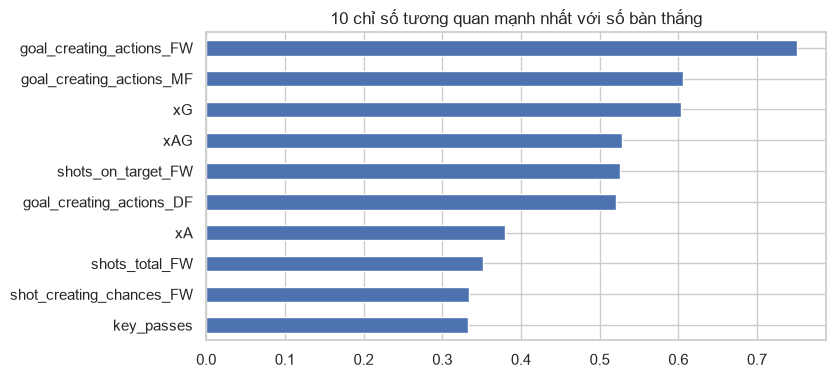

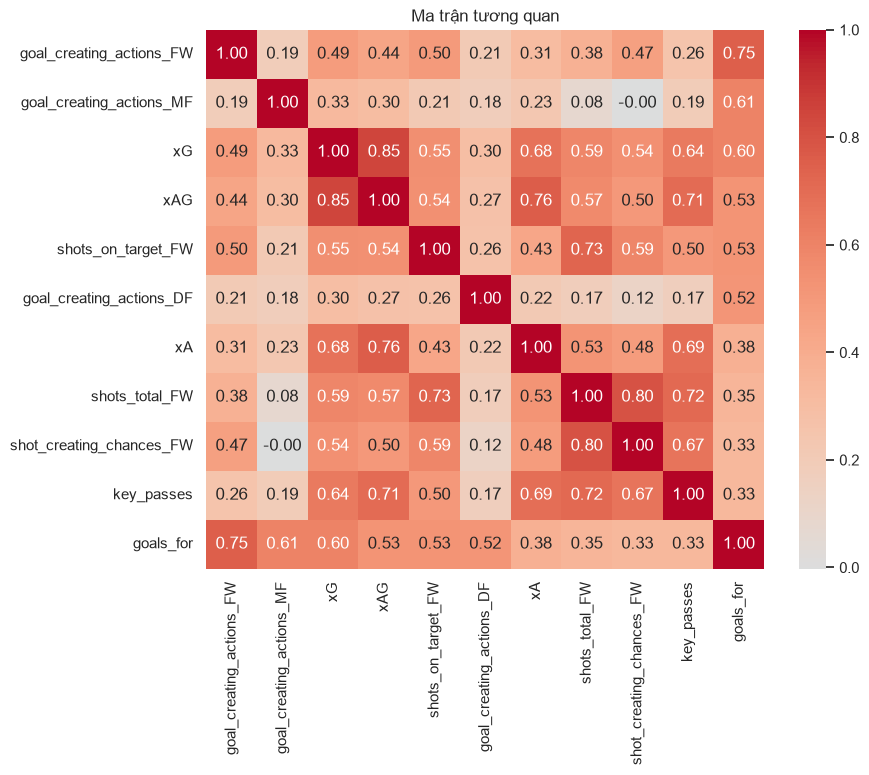

In [12]:
tm = matches[["game_id", "home_team_id", "away_team_id", "home_goals", "away_goals"]].copy()
tm.columns = ["game_id", "m_home_id", "m_away_id", "m_home_goals", "m_away_goals"]

ts = team_stats.merge(tm, on="game_id", how="left")
ts["is_home"] = ts["team_id"] == ts["m_home_id"]
ts["goals_for"] = np.where(ts["is_home"], ts["m_home_goals"], ts["m_away_goals"])
ts["goals_against"] = np.where(ts["is_home"], ts["m_away_goals"], ts["m_home_goals"])

print(ts["is_home"].value_counts())   # mỗi giá trị phải là 2970

drop_cols = ["m_home_goals", "m_away_goals", "goals_against"]
num = ts.select_dtypes("number").drop(columns=drop_cols)

corr = num.corr()["goals_for"].drop("goals_for").dropna().sort_values(ascending=False)
display(corr.head(15).round(3))

corr.head(10).plot.barh(figsize=(8, 4))
plt.gca().invert_yaxis()
plt.title("10 chỉ số tương quan mạnh nhất với số bàn thắng")
plt.savefig("hinh_05_tuongquan.png", dpi=150, bbox_inches="tight")
plt.show()

top = corr.abs().sort_values(ascending=False).head(10).index.tolist() + ["goals_for"]
plt.figure(figsize=(9, 7))
sns.heatmap(num[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Ma trận tương quan")
plt.savefig("hinh_06_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Sau khi ghép team_stats với matches (kiểm tra: mỗi trận có đúng một dòng đội nhà và một dòng đội khách, 2970 mỗi loại), tương quan Pearson giữa các chỉ số của đội và số bàn thắng đội đó ghi được cho thấy: mạnh nhất là goal_creating_actions_FW (r = 0,75), tiếp theo goal_creating_actions_MF (0,61), xG (0,60), xAG (0,53), shots_on_target_FW (0,53) và goal_creating_actions_DF (0,52). Số cú sút trúng đích (0,53) tương quan mạnh hơn tổng số cú sút (0,35), cho thấy chất lượng cú sút quan trọng hơn số lượng. Không chỉ số nào vượt 0,75, nên các chỉ số này chỉ giải thích được một phần số bàn thắng, phần còn lại do yếu tố ngẫu nhiên.

Heatmap cho thấy nhiều chỉ số trùng thông tin nhau: xG và xAG (0,85), shots_total_FW và shot_creating_chances_FW (0,80), xAG và xA (0,76). Đề xuất chỉ giữ một đại diện mỗi nhóm (ví dụ xG) để tránh đa cộng tuyến. Ba chỉ số goal_creating_actions (FW, MF, DF) ít tương quan với nhau nên mang thông tin độc lập.

Lưu ý: (1) goal_creating_actions và shots_on_target có liên hệ gần như theo định nghĩa với bàn thắng, nên r cao phần nào mang tính cơ học; xG phản ánh chất lượng cơ hội đáng tin cậy hơn. (2) Đây là thống kê sau trận, nên không được dùng trực tiếp chỉ số của trận cần dự đoán (data leakage); model chỉ được dùng trung bình các chỉ số của N trận trước đó. (3) Tương quan không phải nhân quả và chỉ đo quan hệ tuyến tính.

# PHONG ĐỘ 5 TRẬN GẦN NHẤT

             gf  gf_last5
gf        1.000     0.218
gf_last5  0.218     1.000


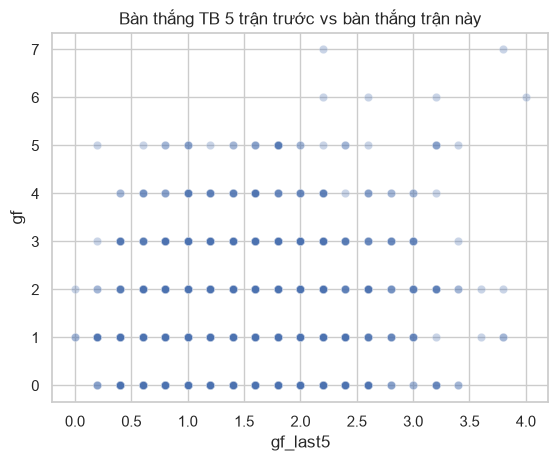

In [13]:
long = long.sort_values(["team", "date"]).reset_index(drop=True)
long["gf_last5"] = long.groupby("team")["gf"].transform(
    lambda s: s.shift(1).rolling(5).mean()
)

print(long[["gf", "gf_last5"]].corr().round(3))

sns.scatterplot(x="gf_last5", y="gf", data=long.sample(1500, random_state=42), alpha=0.3)
plt.title("Bàn thắng TB 5 trận trước vs bàn thắng trận này")
plt.savefig("hinh_07_phongdo.png", dpi=150, bbox_inches="tight")
plt.show()

Tương quan giữa số bàn thắng ở trận hiện tại và trung bình bàn thắng 5 trận trước là r = 0,218, ở mức yếu đến trung bình (r² ≈ 0,05, tức phong độ 5 trận chỉ giải thích khoảng 5% biến thiên số bàn thắng). Biểu đồ phân tán xếp thành các hàng ngang do số bàn thắng là số nguyên, xu hướng tăng có nhưng mờ. Kết luận: phong độ gần đây có giá trị dự báo dương nhưng nhỏ, nên đưa vào feature và kết hợp với các đặc trưng khác; đồng thời cần kỳ vọng thực tế về độ chính xác của model vì tỷ số bóng đá chứa nhiều yếu tố ngẫu nhiên. Lưu ý: tương quan này một phần phản ánh sức mạnh nền của đội (đội mạnh luôn ghi nhiều), nên nhóm model nên thử thêm các cửa sổ 3 và 10 trận, trọng số mũ, hoặc kết hợp với biến sức mạnh đội. Đã dùng shift(1) để chỉ tính các trận trước đó, tránh rò rỉ dữ liệu. Năm trận đầu của mỗi đội không có giá trị gf_last5 nên bị loại khi tính.

# DỮ LIỆU THIẾU CỦA TEAM_STATS

In [14]:
missing = team_stats.isna().mean().sort_values(ascending=False)
display((missing[missing > 0] * 100).round(1).head(15))

save_percentage    3.2
dtype: float64

Trong 96 cột của team_stats, chỉ có save_percentage bị thiếu dữ liệu (3,2%, khoảng 190 trong 5940 dòng); 95 cột còn lại đầy đủ. Đây là chỉ số của thủ môn, nhiều khả năng thiếu khi đội đối thủ không có cú sút trúng đích (phép chia 0/0 không xác định) hoặc do giá trị không hợp lệ đã được đặt NaN ở bước làm sạch. Đề xuất: không điền bằng 0 vì sai ý nghĩa; giữ NaN nếu dùng mô hình cây, hoặc điền bằng trung vị / dùng trung bình trượt N trận đã bỏ qua giá trị thiếu.

# KẾT LUẬN EDA

1. Chất lượng dữ liệu: 2970 trận, không thiếu giá trị ở bảng matches. Mùa 2024-2025 chỉ có 310/380 trận (thiếu khoảng 7 vòng cuối). Bảng team_stats chỉ thiếu save_percentage (3,2%). Tên 31 đội thống nhất.

2. Baseline: đội nhà thắng 44,4%, đội khách thắng 32,7%, hòa 22,9%. Model phải vượt mức 44,4% (luôn đoán đội nhà thắng) mới có giá trị.

3. Phân phối bàn thắng: lệch phải, phổ biến nhất là 1 bàn. Đội nhà trung bình 1,56 bàn (phương sai 1,78), đội khách 1,30 bàn (phương sai 1,49). Phương sai gần trung bình nên phù hợp Poisson Regression. 54,6% trận có hơn 2,5 bàn.

4. Lợi thế sân nhà: trung bình 1,56 điểm ở sân nhà so với 1,21 ở sân khách, nhưng mức độ khác nhau theo đội (cao nhất Arsenal, Tottenham, Liverpool; thấp nhất Burnley, Southampton). Mùa 2020-2021 (không khán giả) là ngoại lệ: lợi thế biến mất, đội khách thắng nhiều hơn đội nhà (40,3% so với 37,9%).

5. Theo mùa: bàn thắng trung bình mỗi trận tăng từ 2,68 (2017-2018) lên 3,28 (2023-2024).

6. Sức mạnh đội: chênh lệch rất lớn giữa Manchester City (2,35 điểm/trận) và nhóm cuối như Norwich (0,57), nên danh tính đội là đặc trưng quan trọng.

7. Chỉ số thống kê: liên quan mạnh nhất tới bàn thắng là goal_creating_actions_FW (0,75), goal_creating_actions_MF (0,61) và xG (0,60). Nhiều chỉ số trùng thông tin nhau (xG-xAG 0,85), nên chọn đại diện mỗi nhóm. Đây là dữ liệu sau trận, nên chỉ được dùng trung bình của các trận trước (tránh data leakage).
8. Phong độ: trung bình 5 trận trước tương quan r = 0,218 với bàn thắng trận sau, yếu nhưng dương, nên dùng làm feature.